In [1]:
import pandas as pd

# استبدل dataset_name باسم الداتا ست والملف الفعلي عندك
df = pd.read_csv('/kaggle/input/datasets/alimohammad4434/alimohammad-csv/gender_submission.csv')
print(df.head())

   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_features=10, n_informative=6, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y, y_hat):
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return -1 / len(y) * np.sum(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

def evaluate_metrics(y_true, y_probs):
    y_pred = (y_probs >= 0.5).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    return acc, prec, rec, f1

# Training - Adam
np.random.seed(42)
m, n = X_train.shape
w, b, lr, epochs = np.zeros(n), 0.0, 0.05, 150
beta1, beta2, epsilon = 0.9, 0.999, 1e-8
v_w, v_b = np.zeros(n), 0.0
s_w, s_b = np.zeros(n), 0.0
loss_history = []

for epoch in range(epochs):
    y_hat = sigmoid(np.dot(X_train, w) + b)
    dw = (1 / m) * np.dot(X_train.T, (y_hat - y_train))
    db = (1 / m) * np.sum(y_hat - y_train)
    
    v_w = beta1 * v_w + (1 - beta1) * dw
    v_b = beta1 * v_b + (1 - beta1) * db
    s_w = beta2 * s_w + (1 - beta2) * (dw ** 2)
    s_b = beta2 * s_b + (1 - beta2) * (db ** 2)
    
    v_w_corr = v_w / (1 - beta1 ** (epoch + 1))
    v_b_corr = v_b / (1 - beta1 ** (epoch + 1))
    s_w_corr = s_w / (1 - beta2 ** (epoch + 1))
    s_b_corr = s_b / (1 - beta2 ** (epoch + 1))
    
    w -= (lr / (np.sqrt(s_w_corr) + epsilon)) * v_w_corr
    b -= (lr / (np.sqrt(s_b_corr) + epsilon)) * v_b_corr
    loss_history.append(compute_loss(y_train, y_hat))

test_probs = sigmoid(np.dot(X_test, w) + b)
print("Adam Test Loss:", compute_loss(y_test, test_probs))
print("Metrics (Acc, Prec, Rec, F1):", evaluate_metrics(y_test, test_probs))

Adam Test Loss: 0.4754426278915393
Metrics (Acc, Prec, Rec, F1): (np.float64(0.8), np.float64(0.7155963302752294), np.float64(0.896551724137931), np.float64(0.7959183673469388))


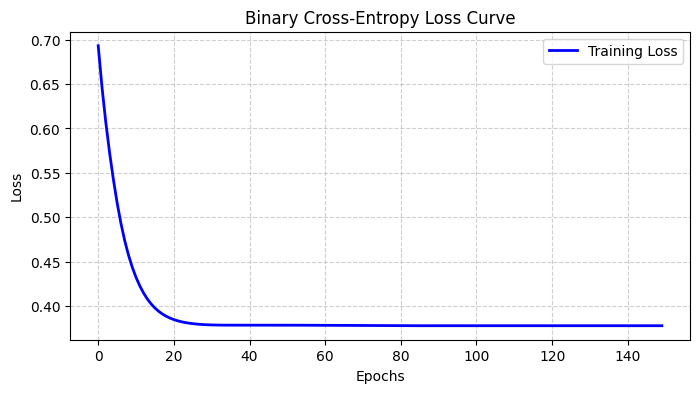

In [3]:
import matplotlib.pyplot as plt

# رسم منحنى الـ Loss
plt.figure(figsize=(8, 4))
plt.plot(loss_history, label='Training Loss', color='blue', linewidth=2)
plt.title('Binary Cross-Entropy Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()